# Fashion classification using neural networks and deep learning

### 1. Import libraries

In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
import tensorflow as tf
from tensorflow import keras

In [3]:
from tensorflow.keras.preprocessing.image import load_img

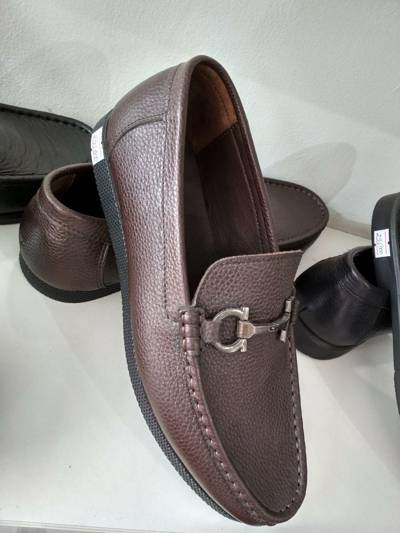

In [5]:
path = './datasets/train/shoes'
name = '2dfbea36-6802-473c-b948-60a1e6181534.jpg'
fullname = f'{path}/{name}'
load_img(fullname)

In [6]:
img = load_img(fullname, target_size=(299,299))

In [7]:
x = np.array(img)
x.shape

(299, 299, 3)

### 2. Pre-trained convolutional neural network

In [8]:
from tensorflow.keras.applications.xception import Xception
from tensorflow.keras.applications.xception import preprocess_input
from tensorflow.keras.applications.xception import decode_predictions

In [9]:
model = Xception(weights='imagenet', input_shape=(299, 299, 3))

91884032/91884032 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step


In [10]:
X = np.array([x])

In [11]:
X.shape

(1, 299, 299, 3)

In [12]:
X = preprocess_input(X)

In [13]:
pred = model.predict(X)

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step


In [14]:
decode_predictions(pred)

35363/35363 ━━━━━━━━━━━━━━━━━━━━ 0s 2us/step


[[('n03680355', 'Loafer', np.float32(0.5640445)),
  ('n04133789', 'sandal', np.float32(0.1558566)),
  ('n02910353', 'buckle', np.float32(0.0650223)),
  ('n03047690', 'clog', np.float32(0.019227294)),
  ('n03527444', 'holster', np.float32(0.016673997))]]

### 3. Transfer learning

In [15]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

In [17]:
train_gen = ImageDataGenerator(preprocessing_function=preprocess_input)

train_ds = train_gen.flow_from_directory(
    './datasets/train',
    target_size=(150, 150),
    batch_size=32
)

Found 3068 images belonging to 10 classes.


In [18]:
train_ds.class_indices

{'dress': 0,
 'hat': 1,
 'longsleeve': 2,
 'outwear': 3,
 'pants': 4,
 'shirt': 5,
 'shoes': 6,
 'shorts': 7,
 'skirt': 8,
 't-shirt': 9}

In [19]:
X, y = next(train_ds)

In [20]:
val_gen = ImageDataGenerator(preprocessing_function=preprocess_input)

val_ds = val_gen.flow_from_directory(
    './datasets/validation',
    target_size=(150, 150),
    batch_size=32,
    shuffle=False
)

Found 341 images belonging to 10 classes.


In [21]:
base_model = Xception(
    weights='imagenet',
    include_top=False,
    input_shape=(150, 150, 3)
)

base_model.trainable = False

inputs = keras.Input(shape=(150, 150, 3))

base = base_model(inputs, training=False)

vectors = keras.layers.GlobalAveragePooling2D()(base)

outputs = keras.layers.Dense(10)(vectors)

model = keras.Model(inputs, outputs)

83683744/83683744 ━━━━━━━━━━━━━━━━━━━━ 5s 0us/step


In [22]:
learning_rate = 0.01
optimizer = keras.optimizers.Adam(learning_rate=learning_rate)

loss = keras.losses.CategoricalCrossentropy(from_logits=True)

model.compile(optimizer=optimizer, loss=loss, metrics=['accuracy'])

In [23]:
history = model.fit(train_ds, epochs=10, validation_data=val_ds)

Epoch 1/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 82s 824ms/step - accuracy: 0.6728 - loss: 1.1840 - val_accuracy: 0.7801 - val_loss: 0.8759
Epoch 2/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 65s 681ms/step - accuracy: 0.8214 - loss: 0.5740 - val_accuracy: 0.7566 - val_loss: 1.0801
Epoch 3/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 66s 691ms/step - accuracy: 0.8686 - loss: 0.4002 - val_accuracy: 0.8006 - val_loss: 0.8215
Epoch 4/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 66s 689ms/step - accuracy: 0.9322 - loss: 0.1917 - val_accuracy: 0.7947 - val_loss: 0.8377
Epoch 5/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 66s 687ms/step - accuracy: 0.9495 - loss: 0.1440 - val_accuracy: 0.7742 - val_loss: 0.9795
Epoch 6/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 66s 686ms/step - accuracy: 0.9674 - loss: 0.0972 - val_accuracy: 0.7889 - val_loss: 0.8580
Epoch 7/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 66s 689ms/step - accuracy: 0.9837 - loss: 0.0588 - val_accuracy: 0.8065 - val_loss: 0.9122
Epoch 8/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 66s 691ms/step - accuracy: 0.9866 - loss: 0.0467 - val_accu

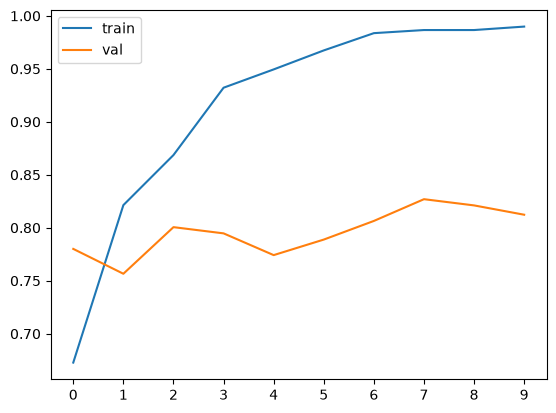

In [26]:
plt.plot(history.history['accuracy'], label='train')
plt.plot(history.history['val_accuracy'], label='val')
plt.xticks(np.arange(10))
plt.legend()

### 4. Adjusting the learning rate

In [24]:
def make_model(learning_rate=0.01):
    base_model = Xception(
        weights='imagenet',
        include_top=False,
        input_shape=(150, 150, 3)
    )

    base_model.trainable = False

    #########################################

    inputs = keras.Input(shape=(150, 150, 3))
    base = base_model(inputs, training=False)
    vectors = keras.layers.GlobalAveragePooling2D()(base)
    outputs = keras.layers.Dense(10)(vectors)
    model = keras.Model(inputs, outputs)
    
    #########################################

    optimizer = keras.optimizers.Adam(learning_rate=learning_rate)
    loss = keras.losses.CategoricalCrossentropy(from_logits=True)

    model.compile(
        optimizer=optimizer,
        loss=loss,
        metrics=['accuracy']
    )
    
    return model

In [27]:
scores = {}

for lr in [0.001, 0.01]:
    print(lr)

    model = make_model(learning_rate=lr)
    history = model.fit(train_ds, epochs=10, validation_data=val_ds)
    scores[lr] = history.history

    print()
    print()

0.001
Epoch 1/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 71s 703ms/step - accuracy: 0.6349 - loss: 1.0906 - val_accuracy: 0.7801 - val_loss: 0.7289
Epoch 2/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 67s 695ms/step - accuracy: 0.7852 - loss: 0.6324 - val_accuracy: 0.8006 - val_loss: 0.6296
Epoch 3/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 67s 697ms/step - accuracy: 0.8243 - loss: 0.5056 - val_accuracy: 0.8035 - val_loss: 0.5986
Epoch 4/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 67s 694ms/step - accuracy: 0.8628 - loss: 0.4288 - val_accuracy: 0.8065 - val_loss: 0.5973
Epoch 5/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 66s 690ms/step - accuracy: 0.8859 - loss: 0.3710 - val_accuracy: 0.8152 - val_loss: 0.5551
Epoch 6/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 66s 686ms/step - accuracy: 0.9029 - loss: 0.3270 - val_accuracy: 0.8152 - val_loss: 0.5489
Epoch 7/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 67s 693ms/step - accuracy: 0.9198 - loss: 0.2906 - val_accuracy: 0.8270 - val_loss: 0.5335
Epoch 8/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 67s 695ms/step - accuracy: 0.9306 - loss: 0.2599 - va

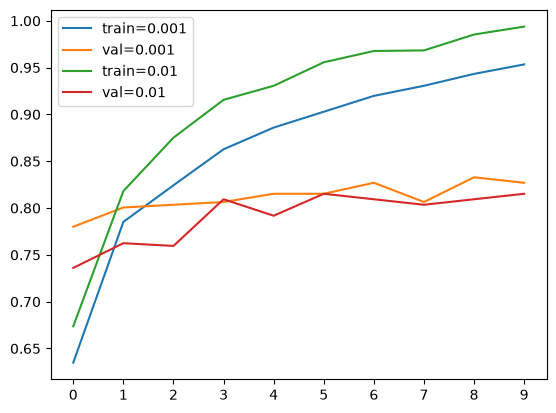

In [28]:
for lr, hist in scores.items():
    plt.plot(hist['accuracy'], label=('train=%s' % lr))
    plt.plot(hist['val_accuracy'], label=('val=%s' % lr))

plt.xticks(np.arange(10))
plt.legend()

In [29]:
learning_rate = 0.001

### 5. Checkpointing

In [32]:
model.save_weights('model_v1.weights.h5')

In [33]:
checkpoint = keras.callbacks.ModelCheckpoint(
    'xception_v1_{epoch:02d}_{val_accuracy:.3f}.h5',
    save_best_only=True,
    monitor='val_accuracy',
    mode='max'
)

In [36]:
learning_rate = 0.001

model = make_model(learning_rate=learning_rate)

history = model.fit(
    train_ds,
    epochs=10,
    validation_data=val_ds,
    callbacks=[checkpoint]
)

Epoch 1/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 652ms/step - accuracy: 0.6842 - loss: 0.9357

96/96 ━━━━━━━━━━━━━━━━━━━━ 78s 750ms/step - accuracy: 0.6842 - loss: 0.9357 - val_accuracy: 0.7742 - val_loss: 0.6513
Epoch 2/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 652ms/step - accuracy: 0.8181 - loss: 0.5169

96/96 ━━━━━━━━━━━━━━━━━━━━ 70s 728ms/step - accuracy: 0.8181 - loss: 0.5169 - val_accuracy: 0.7947 - val_loss: 0.5980
Epoch 3/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 69s 721ms/step - accuracy: 0.8840 - loss: 0.3473 - val_accuracy: 0.7889 - val_loss: 0.5821
Epoch 4/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 653ms/step - accuracy: 0.9208 - loss: 0.2454

96/96 ━━━━━━━━━━━━━━━━━━━━ 71s 737ms/step - accuracy: 0.9208 - loss: 0.2454 - val_accuracy: 0.8065 - val_loss: 0.5477
Epoch 5/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 653ms/step - accuracy: 0.9482 - loss: 0.1823

96/96 ━━━━━━━━━━━━━━━━━━━━ 70s 729ms/step - accuracy: 0.9482 - loss: 0.1823 - val_accuracy: 0.8211 - val_loss: 0.5392
Epoch 6/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 65s 682ms/step - accuracy: 0.9710 - loss: 0.1226 - val_accuracy: 0.8123 - val_loss: 0.5744
Epoch 7/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 606ms/step - accuracy: 0.9840 - loss: 0.0892

96/96 ━━━━━━━━━━━━━━━━━━━━ 65s 677ms/step - accuracy: 0.9840 - loss: 0.0892 - val_accuracy: 0.8240 - val_loss: 0.5652
Epoch 8/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 604ms/step - accuracy: 0.9948 - loss: 0.0554

96/96 ━━━━━━━━━━━━━━━━━━━━ 65s 674ms/step - accuracy: 0.9948 - loss: 0.0554 - val_accuracy: 0.8299 - val_loss: 0.5941
Epoch 9/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 64s 671ms/step - accuracy: 0.9980 - loss: 0.0391 - val_accuracy: 0.8240 - val_loss: 0.5985
Epoch 10/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 65s 672ms/step - accuracy: 0.9993 - loss: 0.0289 - val_accuracy: 0.8152 - val_loss: 0.6350


### 6. Adding more layers

In [37]:
def make_model(learning_rate=0.01, size_inner=100):
    base_model = Xception(
        weights='imagenet',
        include_top=False,
        input_shape=(150, 150, 3)
    )

    base_model.trainable = False

    #########################################

    inputs = keras.Input(shape=(150, 150, 3))
    base = base_model(inputs, training=False)
    vectors = keras.layers.GlobalAveragePooling2D()(base)
    
    inner = keras.layers.Dense(size_inner, activation='relu')(vectors)
    
    outputs = keras.layers.Dense(10)(inner)
    
    model = keras.Model(inputs, outputs)
    
    #########################################

    optimizer = keras.optimizers.Adam(learning_rate=learning_rate)
    loss = keras.losses.CategoricalCrossentropy(from_logits=True)

    model.compile(
        optimizer=optimizer,
        loss=loss,
        metrics=['accuracy']
    )
    
    return model

In [38]:
learning_rate = 0.001

scores = {}

for size in [10, 100]:
    print(size)

    model = make_model(learning_rate=learning_rate, size_inner=size)
    history = model.fit(train_ds, epochs=10, validation_data=val_ds)
    scores[size] = history.history

    print()
    print()

10
Epoch 1/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 68s 679ms/step - accuracy: 0.3996 - loss: 1.6334 - val_accuracy: 0.5748 - val_loss: 1.2085
Epoch 2/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 64s 668ms/step - accuracy: 0.6832 - loss: 0.9778 - val_accuracy: 0.6921 - val_loss: 0.9043
Epoch 3/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 64s 666ms/step - accuracy: 0.7405 - loss: 0.7629 - val_accuracy: 0.7273 - val_loss: 0.8066
Epoch 4/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 64s 669ms/step - accuracy: 0.7748 - loss: 0.6582 - val_accuracy: 0.7566 - val_loss: 0.7233
Epoch 5/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 64s 667ms/step - accuracy: 0.8123 - loss: 0.5737 - val_accuracy: 0.7419 - val_loss: 0.7074
Epoch 6/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 64s 667ms/step - accuracy: 0.8347 - loss: 0.5102 - val_accuracy: 0.7537 - val_loss: 0.6687
Epoch 7/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 64s 667ms/step - accuracy: 0.8537 - loss: 0.4600 - val_accuracy: 0.7625 - val_loss: 0.6482
Epoch 8/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 64s 669ms/step - accuracy: 0.8726 - loss: 0.4167 - val_a

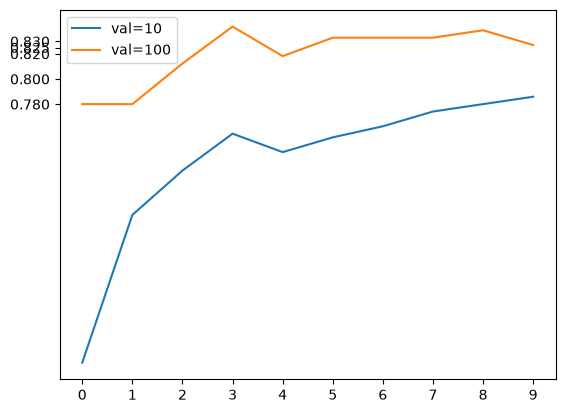

In [39]:
for size, hist in scores.items():
    plt.plot(hist['val_accuracy'], label=('val=%s' % size))

plt.xticks(np.arange(10))
plt.yticks([0.78, 0.80, 0.82, 0.825, 0.83])
plt.legend()

### 7. Adding dropout

In [40]:
def make_model(learning_rate=0.01, size_inner=100, droprate=0.5):
    base_model = Xception(
        weights='imagenet',
        include_top=False,
        input_shape=(150, 150, 3)
    )

    base_model.trainable = False

    #########################################

    inputs = keras.Input(shape=(150, 150, 3))
    base = base_model(inputs, training=False)
    vectors = keras.layers.GlobalAveragePooling2D()(base)
    
    inner = keras.layers.Dense(size_inner, activation='relu')(vectors)
    drop = keras.layers.Dropout(droprate)(inner)
    
    outputs = keras.layers.Dense(10)(drop)
    
    model = keras.Model(inputs, outputs)
    
    #########################################

    optimizer = keras.optimizers.Adam(learning_rate=learning_rate)
    loss = keras.losses.CategoricalCrossentropy(from_logits=True)

    model.compile(
        optimizer=optimizer,
        loss=loss,
        metrics=['accuracy']
    )
    
    return model

In [41]:
learning_rate = 0.001
size = 100

scores = {}

for droprate in [0.0, 0.2]:
    print(droprate)

    model = make_model(
        learning_rate=learning_rate,
        size_inner=size,
        droprate=droprate
    )

    history = model.fit(train_ds, epochs=30, validation_data=val_ds)
    scores[droprate] = history.history

    print()
    print()

0.0
Epoch 1/30
96/96 ━━━━━━━━━━━━━━━━━━━━ 68s 681ms/step - accuracy: 0.6747 - loss: 0.9541 - val_accuracy: 0.7889 - val_loss: 0.6387
Epoch 2/30
96/96 ━━━━━━━━━━━━━━━━━━━━ 64s 670ms/step - accuracy: 0.8204 - loss: 0.5172 - val_accuracy: 0.8094 - val_loss: 0.5651
Epoch 3/30
72/96 ━━━━━━━━━━━━━━━━━━━━ 14s 597ms/step - accuracy: 0.8774 - loss: 0.3692

KeyboardInterrupt: 

### 8. Data Augmentation

In [ ]:
train_gen = ImageDataGenerator(
    preprocessing_function=preprocess_input,
#     vertical_flip=True,
)

train_ds = train_gen.flow_from_directory(
    './datasets/train',
    target_size=(150, 150),
    batch_size=32
)

val_gen = ImageDataGenerator(preprocessing_function=preprocess_input)

val_ds = val_gen.flow_from_directory(
    './datasets/validation',
    target_size=(150, 150),
    batch_size=32,
    shuffle=False
)

In [ ]:
learning_rate = 0.001
size = 100
droprate = 0.2

model = make_model(
    learning_rate=learning_rate,
    size_inner=size,
    droprate=droprate
)

history = model.fit(train_ds, epochs=50, validation_data=val_ds)

In [ ]:
hist = history.history
plt.plot(hist['val_accuracy'], label='val')
plt.plot(hist['accuracy'], label='train')

plt.legend()